<a href="https://colab.research.google.com/github/FadhilTaufiqurrachman/Machine-Learning/blob/main/244107020090_Fadhil_Taufiqurrachman_T14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Praktikum Jobsheet 14

NIM : 244107020090

Nama : Fadhil Taufiqurrachman

Kelas : TI 3G

No Absen : 06

Mata Kuliah : Pembelajaran Mesin

Persiapan Data

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')
BASE_PATH = '/content/drive/MyDrive/Education/Current Semester College File/Machine Learning/'

Mounted at /content/drive


Import Library

In [ ]:
# Import Library Utama Untuk Pemodelan Dan Visualisasi
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models, callbacks

# Cek Versi TensorFlow Dan Ketersediaan GPU
print("Versi TensorFlow:", tf.__version__)
print("GPU Terdeteksi  :", tf.config.list_physical_devices('GPU'))

Versi TensorFlow: 2.21.0
GPU Terdeteksi  : []


### Tugas 1: Modifikasi Model CNN CIFAR-10 (Akurasi Testing > 80%)

Langkah 1.1 - Unduh & Pra-Pengolahan Data CIFAR-10

In [ ]:
# Unduh Dataset CIFAR-10 Dari Keras
(x_train_cifar, y_train_cifar), (x_test_cifar, y_test_cifar) = datasets.cifar10.load_data()

# Normalisasi Nilai Piksel Ke Rentang 0 Sampai 1
x_train_cifar = x_train_cifar.astype('float32') / 255.0
x_test_cifar = x_test_cifar.astype('float32') / 255.0

# Daftar Nama Kelas CIFAR-10
class_names_cifar = ['airplane', 'automobile', 'bird', 'cat', 'deer',
                     'dog', 'frog', 'horse', 'ship', 'truck']

print("Shape Data Training CIFAR-10:", x_train_cifar.shape)
print("Shape Data Testing CIFAR-10 :", x_test_cifar.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2308s 14us/step
Shape Data Training CIFAR-10: (50000, 32, 32, 3)
Shape Data Testing CIFAR-10 : (10000, 32, 32, 3)


Langkah 1.2 - Membangun Arsitektur Model CNN Modifikasi

In [ ]:
# Membuat Pipeline Data Augmentation Berbasis Layer Keras
data_augmentation = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomTranslation(0.1, 0.1)
], name='data_augmentation')

# Membangun Arsitektur CNN Modifikasi Gaya VGG Dengan BatchNorm Dan Dropout
model_cifar = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    # Blok Konvolusi 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Blok Konvolusi 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Blok Konvolusi 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # Blok Fully Connected
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10)
])

# Menampilkan Ringkasan Arsitektur Model Modifikasi
model_cifar.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 128)            │           51

 Total params: 552,874 (2.11 MB)

 Trainable params: 551,722 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

Langkah 1.3 - Compile Model & Pengaturan Callbacks

In [ ]:
# Kompilasi Model Dengan Optimizer Adam Dan Sparse Categorical Crossentropy
model_cifar.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Pengaturan Callbacks Untuk Penyesuaian Learning Rate Dan Pencegahan Overfitting
callbacks_cifar = [
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

Langkah 1.4 - Pelatihan (Fit) Model CIFAR-10

In [ ]:
# Melatih Model Modifikasi Hingga Maksimal 35 Epoch
history_cifar = model_cifar.fit(
    x_train_cifar,
    y_train_cifar,
    batch_size=64,
    epochs=35,
    validation_data=(x_test_cifar, y_test_cifar),
    callbacks=callbacks_cifar
)

Epoch 1/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 263s 331ms/step - accuracy: 0.3967 - loss: 1.7594 - val_accuracy: 0.5103 - val_loss: 1.3604 - learning_rate: 0.0010
Epoch 2/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 261s 334ms/step - accuracy: 0.5683 - loss: 1.2078 - val_accuracy: 0.6263 - val_loss: 1.0832 - learning_rate: 0.0010
Epoch 3/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 261s 333ms/step - accuracy: 0.6466 - loss: 1.0122 - val_accuracy: 0.6704 - val_loss: 0.9884 - learning_rate: 0.0010
Epoch 4/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 269s 342ms/step - accuracy: 0.6839 - loss: 0.9050 - val_accuracy: 0.7539 - val_loss: 0.7138 - learning_rate: 0.0010
Epoch 5/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 260s 333ms/step - accuracy: 0.7100 - loss: 0.8364 - val_accuracy: 0.7333 - val_loss: 0.7983 - learning_rate: 0.0010
Epoch 6/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 269s 341ms/step - accuracy: 0.7344 - loss: 0.7776 - val_accuracy: 0.7673 - val_loss: 0.6697 - learning_rate: 0.0010
Epoch 7/35
782/782 ━━━━━━━━━━━━━━━━━━━━ 266s 340ms/step - accura

Langkah 1.5 - Evaluasi & Visualisasi Hasil CIFAR-10

313/313 - 12s - 38ms/step - accuracy: 0.8831 - loss: 0.3580

Akurasi Testing CIFAR-10: 0.8831 (88.31%)


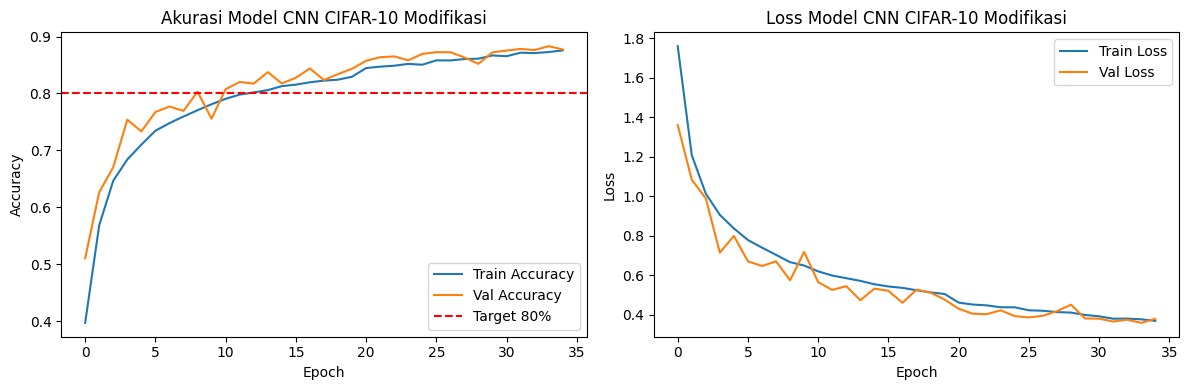

In [ ]:
# Evaluasi Akhir Pada Data Testing CIFAR-10
test_loss_cifar, test_acc_cifar = model_cifar.evaluate(x_test_cifar, y_test_cifar, verbose=2)
print(f"\nAkurasi Testing CIFAR-10: {test_acc_cifar:.4f} ({test_acc_cifar * 100:.2f}%)")

# Visualisasi Kurva Akurasi Dan Loss Training Vs Validasi
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cifar.history['accuracy'], label='Train Accuracy')
plt.plot(history_cifar.history['val_accuracy'], label='Val Accuracy')
plt.axhline(y=0.80, color='r', linestyle='--', label='Target 80%')
plt.title('Akurasi Model CNN CIFAR-10 Modifikasi')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(history_cifar.history['loss'], label='Train Loss')
plt.plot(history_cifar.history['val_loss'], label='Val Loss')
plt.title('Loss Model CNN CIFAR-10 Modifikasi')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

### Tugas 2: Model CNN untuk Klasifikasi Dataset MNIST

Langkah 2.1 - Unduh & Pra-Pengolahan Data MNIST

In [ ]:
# Unduh Dataset MNIST Dari Keras
(x_train_mnist, y_train_mnist), (x_test_mnist, y_test_mnist) = datasets.mnist.load_data()

# Normalisasi Nilai Piksel Ke Rentang 0 Sampai 1
x_train_mnist = x_train_mnist.astype('float32') / 255.0
x_test_mnist = x_test_mnist.astype('float32') / 255.0

# Menambahkan Dimensi Kanal Grayscale Dari (28, 28) Menjadi (28, 28, 1)
x_train_mnist = np.expand_dims(x_train_mnist, axis=-1)
x_test_mnist = np.expand_dims(x_test_mnist, axis=-1)

print("Shape Data Training MNIST:", x_train_mnist.shape)
print("Shape Data Testing MNIST :", x_test_mnist.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shape Data Training MNIST: (60000, 28, 28, 1)
Shape Data Testing MNIST : (10000, 28, 28, 1)


Langkah 2.2 - Verifikasi Data MNIST

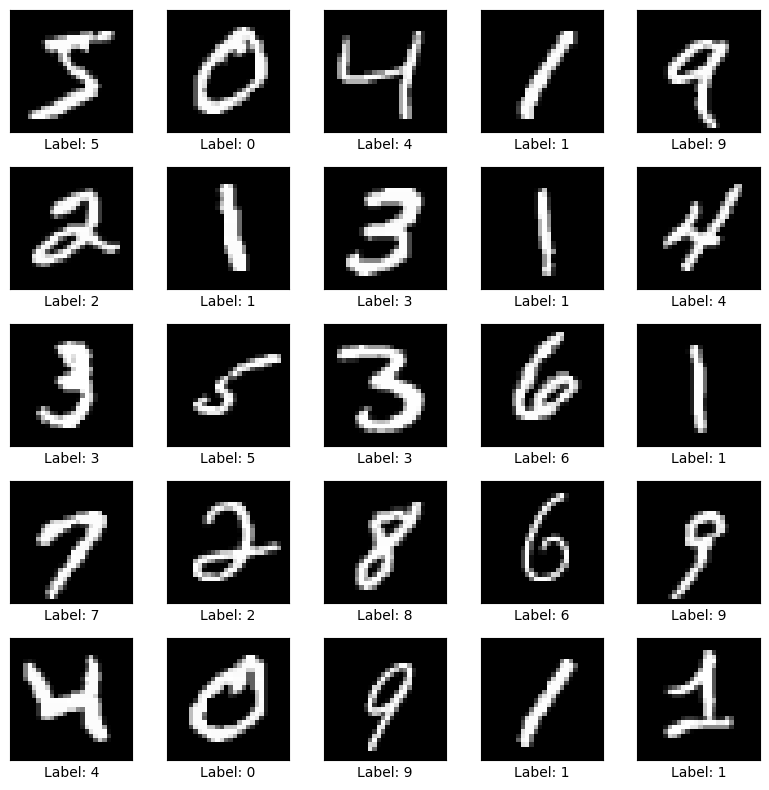

In [ ]:
# Menampilkan 25 Sampel Citra Angka MNIST Beserta Label Aslinya
plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train_mnist[i].squeeze(), cmap='gray')
    plt.xlabel(f"Label: {y_train_mnist[i]}")
plt.tight_layout()
plt.show()

Langkah 2.3 - Membangun Arsitektur Model CNN MNIST

In [ ]:
# Membangun Arsitektur CNN Untuk Klasifikasi Citra Grayscale MNIST
model_mnist = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Blok Konvolusi 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Blok Konvolusi 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Blok Fully Connected
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10)
])

# Menampilkan Ringkasan Arsitektur Model MNIST
model_mnist.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Langkah 2.4 - Compile & Pelatihan (Fit) Model MNIST

In [ ]:
# Kompilasi Model CNN MNIST
model_mnist.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Melatih Model CNN MNIST Selama 10 Epoch
history_mnist = model_mnist.fit(
    x_train_mnist,
    y_train_mnist,
    batch_size=64,
    epochs=10,
    validation_data=(x_test_mnist, y_test_mnist)
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 29s 30ms/step - accuracy: 0.9401 - loss: 0.1955 - val_accuracy: 0.9833 - val_loss: 0.0519
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 40s 29ms/step - accuracy: 0.9801 - loss: 0.0657 - val_accuracy: 0.9874 - val_loss: 0.0388
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 30ms/step - accuracy: 0.9846 - loss: 0.0493 - val_accuracy: 0.9903 - val_loss: 0.0289
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 29ms/step - accuracy: 0.9884 - loss: 0.0373 - val_accuracy: 0.9916 - val_loss: 0.0252
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 29ms/step - accuracy: 0.9905 - loss: 0.0311 - val_accuracy: 0.9911 - val_loss: 0.0250
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 41s 29ms/step - accuracy: 0.9918 - loss: 0.0252 - val_accuracy: 0.9911 - val_loss: 0.0258
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 29s 30ms/step - accuracy: 0.9924 - loss: 0.0231 - val_accuracy: 0.9898 - val_loss: 0.0287
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 27s 29ms/step - accuracy: 0.9939 - loss: 0.0190 - 

Langkah 2.5 - Evaluasi & Visualisasi Hasil MNIST

313/313 - 1s - 5ms/step - accuracy: 0.9915 - loss: 0.0275

Akurasi Testing MNIST: 0.9915 (99.15%)


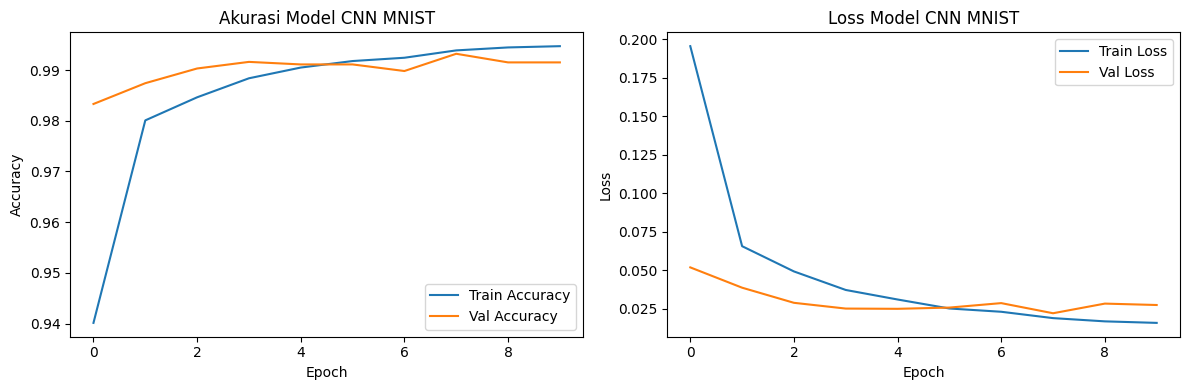

In [ ]:
# Evaluasi Akhir Pada Data Testing MNIST
test_loss_mnist, test_acc_mnist = model_mnist.evaluate(x_test_mnist, y_test_mnist, verbose=2)
print(f"\nAkurasi Testing MNIST: {test_acc_mnist:.4f} ({test_acc_mnist * 100:.2f}%)")

# Visualisasi Kurva Akurasi Dan Loss Model MNIST
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_mnist.history['accuracy'], label='Train Accuracy')
plt.plot(history_mnist.history['val_accuracy'], label='Val Accuracy')
plt.title('Akurasi Model CNN MNIST')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(history_mnist.history['loss'], label='Train Loss')
plt.plot(history_mnist.history['val_loss'], label='Val Loss')
plt.title('Loss Model CNN MNIST')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

Langkah 2.6 - Uji Prediksi Sampel Data Testing MNIST

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


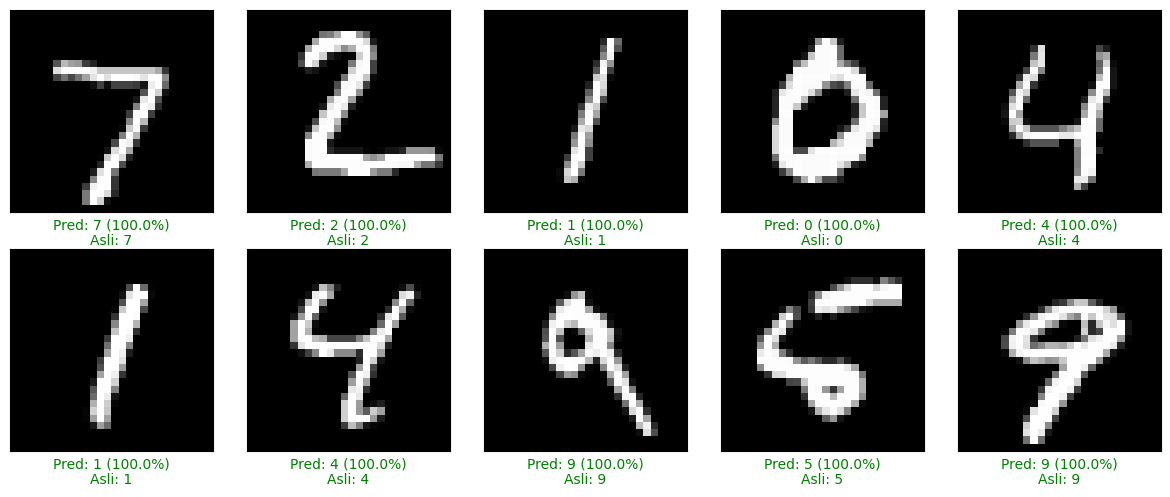

In [ ]:
# Mengubah Output Logits Menjadi Probabilitas Dengan Softmax
prob_model_mnist = models.Sequential([
    model_mnist,
    layers.Softmax()
])

# Melakukan Prediksi Pada 10 Citra Pertama Data Testing
predictions_mnist = prob_model_mnist.predict(x_test_mnist[:10])

# Visualisasi Hasil Prediksi Vs Label Asli
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_test_mnist[i].squeeze(), cmap='gray')

    pred_label = np.argmax(predictions_mnist[i])
    true_label = y_test_mnist[i]
    confidence = np.max(predictions_mnist[i]) * 100
    color = 'green' if pred_label == true_label else 'red'

    plt.xlabel(f"Pred: {pred_label} ({confidence:.1f}%)\nAsli: {true_label}", color=color)

plt.tight_layout()
plt.show()